# Diffusion trained on predicted durations
The first diffusion model learned from FastSpeech mels made with the *true* durations, but in real use it receives mels made with *predicted* durations, a mismatch that makes it change words. Here it learns from exactly what it will see in use: FastSpeech mels with predicted durations, paired with the real mels **time-warped** to that same timing (each character's real frames resampled to its predicted length).

It is saved as a separate model, `diffusion_pred`, so your current diffusion stays as a fallback. The pipeline automatically uses `diffusion_pred` once it exists.

**Restart the kernel**, close other large programs (this needs about 10 GB of RAM), then run the cells in order.

In [1]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - select the Python 3.11.9 kernel")

GPU: NVIDIA GeForce RTX 4070


## Step 1 - make the training data (about 5-10 minutes)
Creates `data/coarse_pred_cache.pt` (about 5 GB).

In [2]:
from vc_lib import train_fastspeech
train_fastspeech.export_coarse_predicted(ROOT)

c:\Users\INTEL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
exporting: 100%|██████████| 1998/1998 [02:53<00:00, 11.52it/s]


Exported 127852 coarse mels with predicted durations + warped real targets


## Step 2 - train (40 epochs, about 25-30 minutes; resumes if interrupted)

[diffusion_pred] training on warped targets (predicted durations)
[diffusion_pred] starting fresh
[diffusion_pred] epoch 1/40  train=0.1467  val=0.0592  (34s)  * best
[diffusion_pred] epoch 2/40  train=0.0494  val=0.0447  (33s)  * best
[diffusion_pred] epoch 3/40  train=0.0467  val=0.0429  (33s)  * best
[diffusion_pred] epoch 4/40  train=0.0454  val=0.0421  (34s)  * best
[diffusion_pred] epoch 5/40  train=0.0442  val=0.0415  (34s)  * best
[diffusion_pred] epoch 6/40  train=0.0438  val=0.0411  (33s)  * best
[diffusion_pred] epoch 7/40  train=0.0439  val=0.0408  (32s)  * best
[diffusion_pred] epoch 8/40  train=0.0431  val=0.0405  (36s)  * best
[diffusion_pred] epoch 9/40  train=0.0432  val=0.0403  (35s)  * best
[diffusion_pred] epoch 10/40  train=0.0429  val=0.0401  (35s)  * best
[diffusion_pred] epoch 11/40  train=0.0427  val=0.0400  (34s)  * best
[diffusion_pred] epoch 12/40  train=0.0426  val=0.0398  (34s)  * best
[diffusion_pred] epoch 13/40  train=0.0423  val=0.0397  (33s)  * best
[

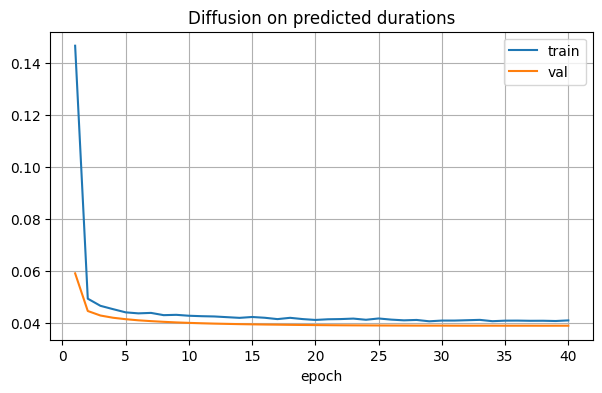

In [3]:
from vc_lib import train_diffusion
from vc_lib.common import paths, plot_history

hist = train_diffusion.train(ROOT, epochs=40, batch_size=32, lr=2e-4,
                             name='diffusion_pred', coarse_file=paths(ROOT)['coarse_pred'])
plot_history(hist, ['train', 'val'], 'Diffusion on predicted durations')

## Step 3 - compare old vs new diffusion at each strength (about 4-5 minutes)
Same 7 sentences as before (the last two are new text). Lower WER = clearer words.

In [4]:
import io, contextlib, numpy as np
from vc_lib.infer import VoicePipeline, evaluate
from vc_lib.common import SR

sentences = ['Please call Stella.', 'The weather is nice today.', 'I will send the report tomorrow morning.',
             'Can you repeat that, please?', 'Your order has been shipped.',
             'The meeting has been moved to Thursday afternoon.', 'Your package will arrive between nine and eleven.']
pipes = {'old': VoicePipeline(ROOT, diffusion='diffusion'), 'new': VoicePipeline(ROOT, diffusion='diffusion_pred')}
spk = pipes['new'].meta['train_speakers'][0]
STRENGTHS = [0.0, 0.1, 0.2, 0.3, 0.5, 1.0]
print(f"{'strength':>8} | {'old WER':>8} {'old perfect':>11} | {'new WER':>8} {'new perfect':>11} {'new similarity':>14}")
best = {}
for s in STRENGTHS:
    row = {}
    for k, pp in pipes.items():
        pp.strength = s
        with contextlib.redirect_stdout(io.StringIO()):
            w, sim = evaluate(pp, sentences, speaker=spk)
        row[k] = (np.mean(w), np.mean(np.array(w) == 0), np.mean(sim))
    best[s] = row['new']
    print(f"{s:>8.1f} | {row['old'][0]:>8.3f} {row['old'][1]:>11.0%} | {row['new'][0]:>8.3f} {row['new'][1]:>11.0%} {row['new'][2]:>14.3f}")

Text-to-mel model: fastspeech | diffusion: diffusion, strength 0.1
Text-to-mel model: fastspeech | diffusion: diffusion_pred, strength 0.1
strength |  old WER old perfect |  new WER new perfect new similarity
     0.0 |    0.083         71% |    0.083         71%          0.779
     0.1 |    0.083         71% |    0.101         71%          0.745
     0.2 |    0.124         57% |    0.124         57%          0.727
     0.3 |    0.171         43% |    0.135         43%          0.725
     0.5 |    0.153         43% |    0.303         29%          0.710
     1.0 |    0.417         29% |    0.796         14%          0.690


## Step 4 - listen
The same new sentence through the new diffusion model at each strength, then the old model at 0.1 for comparison.

In [5]:
from IPython.display import Audio, display
text = 'The meeting has been moved to Thursday afternoon.'
for s in STRENGTHS:
    pipes['new'].strength = s
    print(f'new diffusion, strength {s}')
    display(Audio(pipes['new'].synthesize(text, speaker=spk), rate=SR))
pipes['old'].strength = 0.1
print('old diffusion, strength 0.1')
display(Audio(pipes['old'].synthesize(text, speaker=spk), rate=SR))

new diffusion, strength 0.0


new diffusion, strength 0.1


new diffusion, strength 0.2


new diffusion, strength 0.3


new diffusion, strength 0.5


new diffusion, strength 1.0


old diffusion, strength 0.1
